# Autoportrait 2 — description des autoportraits avec Qwen3-32B (consigne A)

Ce carnet est la **deuxième phase** de l'étude. La première phase,
[autoportrait_qwen3_32b.ipynb](autoportrait_qwen3_32b.ipynb), classe chaque chanson du corpus
d'étude stratifié en `autoportrait`, `pas_autoportrait` ou `je_ne_sais_pas`. Ici, on ne garde
que le **sous-ensemble AUTOPORTRAIT** et on **décrit** chaque autoportrait selon
[consigne_A_description.md](consigne_A_description.md). La réponse doit respecter le schéma
[schema_A_description.json](schema_A_description.json).

| Champ | Valeurs | Question |
|---|---|---|
| `justification` | 1–2 phrases, sans citation | résumé du portrait |
| `registre` | `egotrip`, `introspection`, `manifeste`, `mixte` | sur quel ton se peint-il ? |
| `aspects` | 1 à 4 parmi 12 aspects, **du plus au moins important** | de quoi son portrait est-il fait ? |
| `temporalite` | `present`, `passe`, `trajectoire`, `avenir` | à quel moment de sa vie ? |
| `demarcation` | 0 à 7 figures (liste vide possible) | contre qui se définit-il ? |
| `regard_des_autres` | `oui` / `non` | rapporte-t-il le regard des autres ? |

## Plan

0. **Configuration** : paramètres à régler (en tête de la première cellule) et chemins.
1. **Chargement du sous-ensemble AUTOPORTRAIT** : lecture des résultats de la phase 1
   (`autoportrait_qwen_annotation_{n_source}.csv`), filtrage `etiquette == "autoportrait"`
   et `statut == "ok"`, puis récupération des paroles dans `Rap/corpus.csv` par `source_row_index`.
2. **Échantillonnage : test ou sous-ensemble complet** : `taille_echantillon` entier = test
   tiré au hasard (graine 42) parmi les autoportraits ; `None` = tous les autoportraits.
3. **Annotation** : client vLLM (3.1), pipeline avec reprise (3.2), lancement (3.3).
4. **Synthèse** : distributions de chaque champ et croisement registre × période.

## Paramètres (première cellule)

- `n_source` : taille du lot de phase 1 à exploiter. `12938` = corpus d'étude stratifié complet,
  disponible une fois la campagne de phase 1 terminée. Pour un essai avant la fin de cette campagne,
  on peut prendre un lot déjà terminé (par ex. `1024`).
- `taille_echantillon` : `100` pour le pilote, `None` pour tout le sous-ensemble.
- `workers_par_gpu` : requêtes simultanées par serveur vLLM (≤ `--max-num-seqs`, 12 actuellement).
- `taille_lot` : nombre de chansons soumises à la fois (mémoire), sans effet sur le total.

## Inférence

Mêmes serveurs que la phase 1 : `Qwen/Qwen3-32B` en **mode raisonnement**
(`enable_thinking=True`, `--reasoning-parser qwen3`), GPU 1 sur le port 8016 et GPU 2 sur le port 8017
(`QWEN_BASE_URLS` pour changer). Le carnet ne démarre aucun serveur : **vérifier les GPU avec
`nvidia-smi` avant tout lancement**. Si la campagne de phase 1 tourne encore, les deux phases se
partagent les serveurs et chacune ralentit.

Le schéma A est imposé à vLLM par `response_format` (sortie JSON contrainte), puis **revalidé côté
client** : clés exactes, valeurs dans les listes autorisées, 1 à 4 aspects distincts, démarcations
distinctes, justification non vide, raisonnement présent. Une réponse invalide est retentée
(`max_essais`), puis journalisée en erreur.

## Sorties (`data/results/`, `data/performance/`)

- `autoportrait2_qwen_description_{n}.csv` : une ligne par chanson ; listes jointes par `|`,
  `aspect_principal` (premier aspect), indicatrices 0/1 `aspect_*` et `demarcation_*`, raisonnement.
- `autoportrait2_qwen_description_{n}.json` : mêmes données, listes conservées.
- `autoportrait2_qwen_description_{n}_erreurs.csv` : échecs techniques (relancer pour les retenter).
- `autoportrait2_qwen_description_{n}b.csv` : version « b », annotations seules (lignes `ok`, sans raisonnement
  ni colonnes techniques) ; c'est le fichier lu par les statistiques (étapes 5 et 6).
- `autoportrait2_qwen_description_{n}_distributions.csv` : synthèse (étape 4).
- `autoportrait2_qwen32_reason_{perimetre}_n{n}_{empreinte}.jsonl` : journal de reprise.
- `data/performance/perfGPU_autoportrait2.csv` : performances cumulées d'essai en essai,
  colonnes `date,modele,batch,concurrent,n,chansons/s` (fichier distinct de la phase 1).

`{n}` est le nombre de chansons traitées dans le lot.

In [7]:
# ====================== PARAMÈTRES À RÉGLER ======================
# --- 1. Source : résultats de la phase 1 (autoportrait_qwen3_32b.ipynb) ---
# Lit data/results/autoportrait_qwen_annotation_{n_source}.csv ; 12938 = corpus d'étude stratifié complet.
n_source = 12938
# --- 2. Échantillonnage parmi les autoportraits ---
# None = tous les autoportraits du lot source ; un entier (ex. 100) = test tiré au hasard parmi eux.
taille_echantillon = None
# --- 3. Annotation ---
# Requêtes envoyées en parallèle à CHAQUE serveur vLLM (total = workers_par_gpu × nombre de serveurs).
# Garder workers_par_gpu ≤ --max-num-seqs des serveurs (12 actuellement).
workers_par_gpu = 12
# Nombre maximal de chansons soumises à la fois (mémoire) ; ne change pas le total.
taille_lot = 128
# --- 5–6. Analyse des descriptions (sans inférence) ---
# None = dernier export d'annotation ; un entier impose un lot historique pour l'analyse.
n_analyse_force = None
# ==================================================================

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from IPython.display import display
from queue import Queue
import fcntl
import hashlib
import importlib.util
import json
import os
import time
import urllib.error
import urllib.request

import pandas as pd
from tqdm.auto import tqdm

# Accepte un lancement depuis la racine du dépôt, Rap ou Autoportrait.
candidats = [Path.cwd(), Path.cwd() / 'Autoportrait', Path.cwd() / 'Rap' / 'Autoportrait']
dossiers = [p.resolve() for p in candidats
            if (p / 'consigne_A_description.md').is_file() and (p / 'annoter.py').is_file()]
if len(dossiers) != 1:
    raise RuntimeError('Lancer le carnet depuis la racine du dépôt, Rap ou Rap/Autoportrait.')
dossier = dossiers[0]
corpus_path = dossier.parent / 'corpus.csv'
consigne_path = dossier / 'consigne_A_description.md'
schema_path = dossier / 'schema_A_description.json'
resultats_dir = dossier / 'data' / 'results'
performance_dir = dossier / 'data' / 'performance'
source_path = resultats_dir / f'autoportrait_qwen_annotation_{n_source}.csv'
cumul_path = performance_dir / 'perfGPU_autoportrait2.csv'

urls_configurees = os.environ.get('QWEN_BASE_URLS', os.environ.get(
    'QWEN_BASE_URL', 'http://127.0.0.1:8016/v1,http://127.0.0.1:8017/v1'))
base_urls = [url.strip().rstrip('/') for url in urls_configurees.split(',')]
if any(not url.startswith(('http://', 'https://')) for url in base_urls) or len(set(base_urls)) != len(base_urls):
    raise ValueError('Configurer des URL HTTP(S) distinctes dans QWEN_BASE_URLS.')
modele = 'Qwen/Qwen3-32B'
cle_api = os.environ.get('QWEN_API_KEY', 'EMPTY')
graine = 42
concurrence_par_serveur = workers_par_gpu
concurrence = concurrence_par_serveur * len(base_urls)
serveurs_disponibles = Queue()
for _ in range(concurrence_par_serveur):
    for url in base_urls:
        serveurs_disponibles.put(url)
timeout_secondes = 600
max_tokens = 8192
enable_thinking = True
max_essais = 2

if type(n_source) is not int or n_source <= 0:
    raise ValueError('n_source doit être un entier positif (taille du lot de phase 1).')
if taille_echantillon is not None and (type(taille_echantillon) is not int or taille_echantillon <= 0):
    raise ValueError('taille_echantillon doit être un entier positif, ou None pour tous les autoportraits.')
if n_analyse_force is not None and (type(n_analyse_force) is not int or n_analyse_force <= 0):
    raise ValueError('n_analyse_force doit être un entier positif, ou None pour le dernier export.')
if type(workers_par_gpu) is not int or type(taille_lot) is not int:
    raise ValueError('workers_par_gpu et taille_lot doivent être des entiers positifs.')
if min(taille_lot, concurrence, timeout_secondes, max_tokens, max_essais) <= 0:
    raise ValueError('Les tailles, délais et nombres de tentatives doivent être positifs.')
spec = importlib.util.spec_from_file_location('autoportrait_source', dossier / 'annoter.py')
if spec is None or spec.loader is None:
    raise ImportError('Impossible de charger annoter.py.')
source = importlib.util.module_from_spec(spec)
spec.loader.exec_module(source)
consigne = consigne_path.read_text(encoding='utf-8').strip()
if not consigne:
    raise ValueError('La consigne A est vide.')
schema = json.loads(schema_path.read_text(encoding='utf-8'))
champs = list(schema['required'])
proprietes = schema['properties']
if set(champs) != set(proprietes) or champs[0] != 'justification':
    raise ValueError('Schéma A inattendu : champs requis et propriétés doivent coïncider.')
champs_simples = [c for c in champs if proprietes[c]['type'] == 'string' and 'enum' in proprietes[c]]
champs_listes = [c for c in champs if proprietes[c]['type'] == 'array']
modalites = {c: proprietes[c]['enum'] for c in champs_simples}
modalites |= {c: proprietes[c]['items']['enum'] for c in champs_listes}

def sans_unique_items(noeud):
    # xgrammar (vLLM) refuse « uniqueItems » ; l'unicité est vérifiée côté client par valider_description.
    if isinstance(noeud, dict):
        return {k: sans_unique_items(v) for k, v in noeud.items() if k != 'uniqueItems'}
    return [sans_unique_items(v) for v in noeud] if isinstance(noeud, list) else noeud

schema_serveur = sans_unique_items(schema)
contrainte = {'response_format': {'type': 'json_schema',
              'json_schema': {'name': 'description_autoportrait', 'schema': schema_serveur, 'strict': True}}}
print('Dossier :', dossier)
print('Source phase 1 :', source_path.name)
print('Modèle :', modele, '| endpoints :', base_urls, '| raisonnement :', enable_thinking)
print('Workers :', concurrence, 'au total |', workers_par_gpu, 'par GPU/serveur')
print('Champs :', champs)

Dossier : /home/cbenavent/test/Rap/Autoportrait
Source phase 1 : autoportrait_qwen_annotation_12938.csv
Modèle : Qwen/Qwen3-32B | endpoints : ['http://127.0.0.1:8016/v1', 'http://127.0.0.1:8017/v1'] | raisonnement : True
Workers : 24 au total | 12 par GPU/serveur
Champs : ['justification', 'registre', 'aspects', 'temporalite', 'demarcation', 'regard_des_autres']


## 1. Chargement du sous-ensemble AUTOPORTRAIT

On lit les résultats de la phase 1 pour le lot `n_source`
(`data/results/autoportrait_qwen_annotation_{n_source}.csv`, produit par
[autoportrait_qwen3_32b.ipynb](autoportrait_qwen3_32b.ipynb)) et on garde les chansons
**étiquetées `autoportrait` avec `statut == "ok"`**. Les `pas_autoportrait`, `je_ne_sais_pas`
et éventuelles erreurs techniques de la phase 1 sont écartés.

Ce CSV ne contient pas les paroles : on les relit dans `Rap/corpus.csv` par `source_row_index`
(position de la ligne de données, à partir de 0) avec `lire_corpus`, puis on applique le même
nettoyage qu'en phase 1 (`nettoyer`, sans troncature). On **vérifie** que l'artiste et le titre
relus correspondent à ceux de la phase 1 : un écart signale un corpus modifié entre les deux phases
et arrête le carnet.

La justification de phase 1 est conservée sous le nom `justification_phase1` pour la comparer à la
description. Le tableau final donne le nombre d'autoportraits par année.

Si le fichier source n'existe pas encore (campagne de phase 1 en cours), la cellule liste les lots
disponibles : choisir l'un d'eux dans `n_source` pour un essai.

Aucune inférence n'est lancée à cette étape.

In [8]:
if not source_path.is_file():
    disponibles = sorted(int(p.stem.rsplit('_', 1)[1]) for p in resultats_dir.glob('autoportrait_qwen_annotation_*.csv')
                         if p.stem.rsplit('_', 1)[1].isdigit())
    raise FileNotFoundError(f'{source_path.name} absent (phase 1 non terminée ?). Lots disponibles pour n_source : {disponibles}')
phase1 = pd.read_csv(source_path, dtype={'annee': 'string'}, keep_default_na=False, encoding='utf-8-sig')
colonnes_requises = {'source_row_index', 'artiste', 'titre', 'annee', 'etiquette', 'statut', 'justification'}
if not colonnes_requises <= set(phase1.columns):
    raise ValueError(f'Colonnes manquantes dans {source_path.name} : {sorted(colonnes_requises - set(phase1.columns))}')
if phase1['source_row_index'].duplicated().any():
    raise ValueError('source_row_index en double dans le fichier de phase 1.')
autoportraits = phase1.loc[(phase1['statut'] == 'ok') & (phase1['etiquette'] == 'autoportrait')]
if autoportraits.empty:
    raise ValueError('Aucun autoportrait dans le lot source.')

ids_auto = set(autoportraits['source_row_index'].astype(int))
textes = source.lire_corpus(corpus_path, ids_auto)
chansons = []
for ligne in tqdm(autoportraits.itertuples(index=False), total=len(autoportraits), desc='Paroles', unit='chansons'):
    position = int(ligne.source_row_index)
    texte = textes.get(position)
    if texte is None or (texte['artiste'], texte['titre']) != (ligne.artiste, ligne.titre):
        raise RuntimeError(f'Chanson {position} introuvable ou différente dans corpus.csv : corpus modifié depuis la phase 1 ?')
    paroles = source.nettoyer(texte['paroles'])
    if not paroles:
        raise RuntimeError(f'Paroles vides après nettoyage pour la chanson {position}.')
    chansons.append({'source_row_index': position, 'artiste': ligne.artiste, 'titre': ligne.titre,
                     'annee': ligne.annee, 'mots_nettoyes': len(paroles.split()),
                     'justification_phase1': ligne.justification, 'paroles': paroles})

comptes_phase1 = phase1.loc[phase1['statut'] == 'ok', 'etiquette'].value_counts()
print(f'Phase 1 ({source_path.name}) : {len(phase1)} chansons ; étiquettes valides : {comptes_phase1.to_dict()}')
print(f'Sous-ensemble AUTOPORTRAIT : {len(chansons)} chansons '
      f"({100 * len(chansons) / max(int(comptes_phase1.sum()), 1):.1f} % des annotations valides) ; paroles relues et vérifiées.")
par_annee = pd.Series([c['annee'] or 'NA' for c in chansons]).value_counts().sort_index().rename('autoportraits')
par_annee.index.name = 'annee'
with pd.option_context('display.max_rows', None):
    display(par_annee.to_frame().T)
print('Aucune inférence lancée.')

Paroles:   0%|          | 0/8861 [00:00<?, ?chansons/s]

Phase 1 (autoportrait_qwen_annotation_12938.csv) : 12938 chansons ; étiquettes valides : {'autoportrait': 8861, 'pas_autoportrait': 3887, 'je_ne_sais_pas': 183}
Sous-ensemble AUTOPORTRAIT : 8861 chansons (68.5 % des annotations valides) ; paroles relues et vérifiées.


annee,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
autoportraits,7,16,5,21,16,70,60,119,188,154,...,393,383,343,372,398,380,385,394,403,395


Aucune inférence lancée.


## 2. Échantillonnage : test ou sous-ensemble complet

- `taille_echantillon = None` : **tous** les autoportraits du lot source (périmètre `autoportraits`).
- `taille_echantillon` entier (par ex. `100`) : **test** tiré au hasard parmi les autoportraits avec la
  graine 42 (périmètre `autoportraits_test`), dans l'ordre du corpus. Le même réglage redonne le même tirage.

Le nom des fichiers de sortie dépend de la taille du lot traité :
`autoportrait2_qwen_description_{n}`. Aucune inférence n'est lancée à cette étape.

**Pondération** : le corpus d'étude sur-représente les années avant 2004 (toutes gardées) par rapport aux
années suivantes (500 par an). Les proportions globales de l'étape 4 décrivent donc le corpus d'étude,
pas toute la base ; le croisement par période permet de les lire séparément.

In [9]:
if taille_echantillon is None:
    selection = chansons
    perimetre = 'autoportraits'
else:
    if not taille_echantillon <= len(chansons):
        raise ValueError(f'taille_echantillon doit être compris entre 1 et {len(chansons)} (autoportraits disponibles), ou None.')
    indices = sorted(pd.Series(range(len(chansons))).sample(n=taille_echantillon, random_state=graine).tolist())
    selection = [chansons[i] for i in indices]
    perimetre = 'autoportraits_test'
mode_lancement = 'sous-ensemble complet' if taille_echantillon is None else 'test'
print(f'Périmètre : {perimetre} ({mode_lancement}) ; {len(selection)} chansons sur {len(chansons)} autoportraits.')
print(f'Export prévu : autoportrait2_qwen_description_{len(selection)} — aucune inférence lancée à cette étape.')
display(pd.DataFrame(selection)[['source_row_index', 'artiste', 'titre', 'annee', 'mots_nettoyes']].head(10))

Périmètre : autoportraits (sous-ensemble complet) ; 8861 chansons sur 8861 autoportraits.
Export prévu : autoportrait2_qwen_description_8861 — aucune inférence lancée à cette étape.


,source_row_index,artiste,titre,annee,mots_nettoyes
0,0,Dry,94310,2012,673
1,5,Lynda,A ma place,2014,496
2,18,PLK,1€ / 1Eu,2024,472
3,19,PLK,Une pêche une patate,2024,483
4,29,Rim’K,Jour de pluie,2024,546
5,53,Zamdane,Printemps,2024,475
6,55,orphevre,L’EAU QUI DORT,2022,412
7,68,S-Tee (FRA),TERRAIN VAGUE,2024,381
8,69,S-Tee (FRA),TRAP À LA MORT,2024,340
9,86,Battso,Avengers (il faut sauver le Rap Français),2014,1170


## 3. Annotation

### 3.1 Client vLLM et validation de la description

Chaque requête envoie la consigne A en message système et les paroles nettoyées en message
utilisateur (même format qu'en phase 1), avec `temperature=0`, `seed=42`, `max_tokens=8192` et le
raisonnement activé (`chat_template_kwargs.enable_thinking`). Le schéma A est imposé par
`response_format` (`json_schema`, `strict`). **Le moteur de grammaire de vLLM (xgrammar) refuse le
mot-clé `uniqueItems`** (erreur HTTP 400 « Grammar error: Unimplemented keys ») : le serveur reçoit donc
une copie du schéma sans ce mot-clé (`schema_serveur`), et l'absence de doublons est contrôlée ici.
Le fichier `schema_A_description.json` n'est pas modifié.

La réponse est revalidée côté client à partir du schéma lui-même :

- génération terminée (`finish_reason == "stop"`) et raisonnement non vide ;
- exactement les six clés du schéma ;
- `justification` texte non vide ;
- `registre`, `temporalite`, `regard_des_autres` dans leurs valeurs autorisées ;
- `aspects` : 1 à 4 valeurs autorisées, sans doublon, **ordre conservé** (du plus au moins important) ;
- `demarcation` : valeurs autorisées sans doublon, liste vide acceptée.

Les serveurs sont répartis par une file : chaque worker prend un serveur libre, ce qui équilibre la
charge entre les deux GPU. Les erreurs HTTP transitoires (408, 429, 5xx) et les réponses invalides
sont retentées.

In [10]:
ouvreur = urllib.request.build_opener(urllib.request.ProxyHandler({}))

def appeler_api(route, corps=None, *, serveur):
    requete = urllib.request.Request(
        serveur + route,
        data=None if corps is None else json.dumps(corps).encode('utf-8'),
        headers={'Content-Type': 'application/json', 'Authorization': f'Bearer {cle_api}'},
    )
    with ouvreur.open(requete, timeout=timeout_secondes) as reponse:
        return json.loads(reponse.read().decode('utf-8'))

def verifier_endpoint(serveur):
    try:
        reponse = appeler_api('/models', serveur=serveur)
    except urllib.error.HTTPError as exc:
        raise RuntimeError(f'Serveur vLLM : HTTP {exc.code} sur {serveur}/models. Vérifier la configuration et la clé API.') from exc
    except (urllib.error.URLError, OSError) as exc:
        raise RuntimeError(
            f'Serveur Qwen injoignable sur {serveur}. Démarrer vLLM avec --reasoning-parser qwen3 '
            'sur un GPU libre, attendre sa disponibilité, puis relancer la cellule. '
            'Le notebook ne démarre pas le serveur automatiquement.') from exc
    modeles = [item['id'] for item in reponse['data']]
    if modele not in modeles:
        raise RuntimeError(f'{modele} non servi sur {serveur}. Modèles disponibles : {modeles}')
    print('Serveur disponible :', serveur, '|', modele)

def verifier_serveur():
    for serveur in base_urls:
        verifier_endpoint(serveur)

def valider_description(objet, raisonnement):
    if enable_thinking and (not isinstance(raisonnement, str) or not raisonnement.strip()):
        raise ValueError('Raisonnement absent : vérifier enable_thinking et --reasoning-parser qwen3 côté serveur.')
    if not isinstance(objet, dict) or set(objet) != set(champs):
        raise ValueError(f'Clés exactes attendues : {champs}.')
    if not isinstance(objet['justification'], str) or not objet['justification'].strip():
        raise ValueError('Justification vide ou non textuelle.')
    description = {'justification': objet['justification'].strip()}
    for champ in champs_simples:
        if objet[champ] not in modalites[champ]:
            raise ValueError(f'{champ} inconnu : {objet[champ]!r}')
        description[champ] = objet[champ]
    for champ in champs_listes:
        valeurs = objet[champ]
        bornes = proprietes[champ].get('minItems', 0), proprietes[champ].get('maxItems', len(modalites[champ]))
        if not isinstance(valeurs, list) or not bornes[0] <= len(valeurs) <= bornes[1]:
            raise ValueError(f'{champ} : liste de {bornes[0]} à {bornes[1]} valeurs attendue.')
        if len(set(valeurs)) != len(valeurs) or any(v not in modalites[champ] for v in valeurs):
            raise ValueError(f'{champ} : valeurs inconnues ou répétées : {valeurs!r}')
        description[champ] = list(valeurs)
    description['raisonnement'] = raisonnement.strip() if isinstance(raisonnement, str) else ''
    return description

def valider_reponse(reponse):
    choix = reponse['choices'][0]
    if choix.get('finish_reason') != 'stop':
        raise ValueError(f"Génération incomplète : {choix.get('finish_reason')!r}")
    message = choix['message']
    if not isinstance(message['content'], str):
        raise ValueError('Contenu absent ou non textuel.')
    return valider_description(json.loads(message['content']),
                               message.get('reasoning') or message.get('reasoning_content'))

def annoter_chanson(chanson):
    serveur = serveurs_disponibles.get()
    try:
        return {**annoter_sur_serveur(chanson, serveur), 'serveur': serveur}
    finally:
        serveurs_disponibles.put(serveur)

def description_vide():
    return {'justification': '', **{c: '' for c in champs_simples}, **{c: [] for c in champs_listes}, 'raisonnement': ''}

def annoter_sur_serveur(chanson, serveur):
    debut = time.perf_counter()
    corps = {
        'model': modele,
        'messages': source.messages(consigne, chanson['paroles'], False),
        'temperature': 0, 'seed': graine, 'max_tokens': max_tokens,
        'chat_template_kwargs': {'enable_thinking': enable_thinking},
        **contrainte,
    }
    for essai in range(1, max_essais + 1):
        try:
            reponse = appeler_api('/chat/completions', corps, serveur=serveur)
            return {**valider_reponse(reponse), 'statut': 'ok', 'erreur': '', 'essais': essai,
                    'secondes': time.perf_counter() - debut}
        except urllib.error.HTTPError as exc:
            erreur = f'HTTP {exc.code} : {exc.read().decode("utf-8", "replace")[:1000]}'
            if exc.code not in {408, 429, 500, 502, 503, 504}:
                break
        except (OSError, ValueError, KeyError, IndexError, TypeError) as exc:
            erreur = f'{type(exc).__name__} : {exc}'
        if essai < max_essais:
            time.sleep(2 * essai)
    return {**description_vide(), 'statut': 'erreur', 'erreur': erreur, 'essais': essai,
            'secondes': time.perf_counter() - debut}

### 3.2 Pipeline : journal, reprise et exports

- **Empreinte** : condensat de la configuration (modèle, serveurs, consigne A, schéma A,
  `annoter.py`, paramètres de génération, lot source et sélection). Elle nomme le journal
  `autoportrait2_qwen32_reason_{perimetre}_n{n}_{empreinte}.jsonl` : changer la consigne, le schéma
  ou la sélection ouvre un nouveau journal au lieu de mélanger des résultats incompatibles.
- **Reprise** : chaque résultat est écrit et synchronisé sur disque dès son arrivée. À la relance, les
  réussites du journal sont revalidées et reprises ; seules les chansons absentes ou en erreur sont
  renvoyées au modèle. Une interruption ne perd donc rien.
- **Verrou** : `autoportrait2_qwen_description_{n}.lock` empêche deux exécutions simultanées d'écrire
  les mêmes fichiers.
- **Exports** :
  - CSV : listes jointes par `|`, `aspect_principal` = premier aspect cité, indicatrices 0/1
    `aspect_*` et `demarcation_*` ;
  - JSON : listes conservées ;
  - CSV des erreurs.
- **Performances** : une ligne `date,modele,batch,concurrent,n,chansons/s` est ajoutée à
  `data/performance/perfGPU_autoportrait2.csv` à chaque essai, de sorte que les mesures
  s'accumulent. `chansons/s` est vide si tout a été repris du journal.

In [11]:
def empreinte(selection):
    configuration = {
        'version_pipeline': 1, 'tache': 'consigne_A_description', 'modele': modele, 'urls': base_urls,
        'consigne': consigne, 'schema': schema, 'contrainte': contrainte,
        'annoter_sha256': hashlib.sha256((dossier / 'annoter.py').read_bytes()).hexdigest(),
        'temperature': 0, 'seed': graine, 'max_tokens': max_tokens, 'enable_thinking': enable_thinking,
        'source': source_path.name, 'selection': selection,
    }
    return hashlib.sha256(json.dumps(configuration, ensure_ascii=False, sort_keys=True).encode()).hexdigest()

def tableau_export(resultats):
    tableau = pd.DataFrame(resultats)
    for champ in champs_listes:
        for valeur in modalites[champ]:
            tableau[f'{champ.removesuffix("s")}_{valeur}'] = tableau[champ].map(lambda liste, v=valeur: int(v in liste))
    tableau.insert(tableau.columns.get_loc('aspects') + 1, 'aspect_principal',
                   tableau['aspects'].map(lambda liste: liste[0] if liste else ''))
    for champ in champs_listes:
        tableau[champ] = tableau[champ].map('|'.join)
    return tableau

colonnes_techniques = ['mots_nettoyes', 'justification_phase1', 'raisonnement', 'statut', 'erreur', 'essais',
                        'secondes', 'serveur', 'modele', 'empreinte', 'date_utc']

def executer_description(selection, perimetre):
    if not selection:
        raise ValueError('Sélection vide.')
    resultats_dir.mkdir(parents=True, exist_ok=True)
    performance_dir.mkdir(parents=True, exist_ok=True)
    signature = empreinte(selection)
    mode = 'reason' if enable_thinking else 'sans_reason'
    prefixe = f'autoportrait2_qwen32_{mode}_{perimetre}_n{len(selection)}_{signature[:12]}'
    prefixe_sortie = f'autoportrait2_qwen_description_{len(selection)}'
    journal = resultats_dir / f'{prefixe}.jsonl'
    ids = [c['source_row_index'] for c in selection]
    ids_selection = set(ids)
    if len(ids) != len(ids_selection):
        raise ValueError('Sélection avec doublons.')
    debut = time.perf_counter()
    with (resultats_dir / f'{prefixe_sortie}.lock').open('a') as verrou:
        try:
            fcntl.flock(verrou, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError as exc:
            raise RuntimeError('Un lot de même taille écrit déjà ces fichiers de sortie.') from exc
        resultats = {}
        if journal.exists():
            with journal.open(encoding='utf-8') as fichier:
                for numero, ligne in enumerate(fichier, 1):
                    try:
                        resultat = json.loads(ligne)
                    except json.JSONDecodeError as exc:
                        raise ValueError(f'Journal endommagé : {journal}, ligne {numero}. Réparer avant reprise.') from exc
                    if resultat['empreinte'] != signature or resultat['source_row_index'] not in ids_selection:
                        raise ValueError('Journal incompatible avec la sélection courante.')
                    if resultat['statut'] not in {'ok', 'erreur'}:
                        raise ValueError('Statut invalide dans le journal.')
                    if resultat['statut'] == 'ok':
                        valider_description({c: resultat[c] for c in champs}, resultat.get('raisonnement'))
                    resultats[resultat['source_row_index']] = resultat
        restantes = [c for c in selection if resultats.get(c['source_row_index'], {}).get('statut') != 'ok']
        reprises = len(selection) - len(restantes)
        print(f'{perimetre} : {reprises} réussites reprises ; {len(restantes)} chansons à traiter.')
        if restantes:
            verifier_serveur()
        traitees = erreurs = 0
        with journal.open('a', encoding='utf-8') as fichier:
            with ThreadPoolExecutor(max_workers=concurrence) as executeur:
                taches = {}
                try:
                    with tqdm(total=len(selection), initial=reprises, desc=f'Description {perimetre}',
                              unit='chansons', mininterval=0.5) as barre:
                        for debut_lot in range(0, len(restantes), taille_lot):
                            lot = restantes[debut_lot:debut_lot + taille_lot]
                            taches = {executeur.submit(annoter_chanson, c): c for c in lot}
                            for tache in as_completed(taches):
                                chanson = taches[tache]
                                resultat = {**{k: v for k, v in chanson.items() if k != 'paroles'},
                                            **tache.result(), 'modele': modele, 'empreinte': signature,
                                            'date_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())}
                                fichier.write(json.dumps(resultat, ensure_ascii=False) + '\n')
                                fichier.flush()
                                os.fsync(fichier.fileno())
                                resultats[chanson['source_row_index']] = resultat
                                traitees += 1
                                erreurs += resultat['statut'] == 'erreur'
                                barre.update(1)
                                barre.set_postfix(erreurs=erreurs,
                                    chansons_s=f'{traitees / max(time.perf_counter() - debut, 1e-9):.2f}', refresh=False)
                except BaseException:
                    for tache in taches:
                        tache.cancel()
                    raise
        ordonnes = [resultats[position] for position in ids]
        if len(ordonnes) != len(selection):
            raise RuntimeError('Effectif final incohérent.')
        tableau = tableau_export(ordonnes)
        tableau.to_csv(resultats_dir / f'{prefixe_sortie}.csv', index=False, encoding='utf-8-sig')
        (resultats_dir / f'{prefixe_sortie}.json').write_text(
            json.dumps(ordonnes, ensure_ascii=False, indent=2), encoding='utf-8')
        tableau.loc[tableau['statut'] == 'erreur'].to_csv(
            resultats_dir / f'{prefixe_sortie}_erreurs.csv', index=False, encoding='utf-8-sig')
        tableau.loc[tableau['statut'] == 'ok'].drop(columns=colonnes_techniques, errors='ignore').to_csv(
            resultats_dir / f'{prefixe_sortie}b.csv', index=False, encoding='utf-8-sig')
        secondes = time.perf_counter() - debut
        metriques = {'perimetre': perimetre, 'source': source_path.name, 'modele': modele, 'empreinte': signature,
                     'selection': len(selection), 'reprises': reprises, 'traitees_session': traitees,
                     'reussites': int((tableau['statut'] == 'ok').sum()),
                     'erreurs': int((tableau['statut'] == 'erreur').sum()),
                     'secondes_session_client': secondes, 'chansons_s_session': traitees / secondes,
                     'date_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
                     'type_execution': 'reprise_cache' if not traitees else ('mixte' if reprises else 'calcul'),
                     'nombre_serveurs': len(base_urls), 'concurrence': concurrence,
                     'concurrence_par_serveur': concurrence_par_serveur, 'taille_lot': taille_lot,
                     'max_tokens': max_tokens, 'enable_thinking': enable_thinking,
                     'raisonnements_non_vides': int(tableau['raisonnement'].str.strip().ne('').sum())}
        performance_essai = pd.DataFrame([{
            'date': metriques['date_utc'], 'modele': modele, 'batch': taille_lot,
            'concurrent': concurrence, 'n': len(selection),
            'chansons/s': traitees / secondes if traitees else None,
        }])
        with cumul_path.open('a+', encoding='utf-8', newline='') as cumul:
            fcntl.flock(cumul, fcntl.LOCK_EX)
            cumul.seek(0, os.SEEK_END)
            vide = cumul.tell() == 0
            if not vide:
                cumul.seek(0)
                if list(pd.read_csv(cumul, nrows=0).columns) != list(performance_essai.columns):
                    raise ValueError(f'Colonnes incompatibles dans {cumul_path}. Corriger le fichier avant de relancer.')
            cumul.seek(0, os.SEEK_END)
            performance_essai.to_csv(cumul, index=False, header=vide)
            cumul.flush()
            os.fsync(cumul.fileno())
    display(pd.DataFrame([metriques]))
    if metriques['erreurs']:
        print('ATTENTION : erreurs techniques présentes ; voir le CSV erreurs et relancer pour les retenter.')
    print('Descriptions :', resultats_dir / f'{prefixe_sortie}.csv')
    print('Performances cumulées :', cumul_path)
    return ordonnes, tableau

### 3.3 Lancement

**Avant de lancer : vérifier les GPU (`nvidia-smi`) et que les deux serveurs répondent sur `/v1/models`.**
La cellule décrit la sélection de l'étape 2 ; relancer la même cellule reprend un lot interrompu.
Elle s'arrête en erreur si des chansons restent en échec, après avoir écrit tous les fichiers.

In [12]:
descriptions, resultats = executer_description(selection, perimetre)
display(resultats[['source_row_index', 'artiste', 'titre', 'annee', 'registre', 'aspects',
                   'temporalite', 'demarcation', 'regard_des_autres', 'justification', 'erreur']].head(20))
if not resultats['statut'].eq('ok').all():
    raise RuntimeError('Lot incomplet : consulter le fichier erreurs et relancer pour reprendre.')

autoportraits : 0 réussites reprises ; 8861 chansons à traiter.
Serveur disponible : http://127.0.0.1:8016/v1 | Qwen/Qwen3-32B
Serveur disponible : http://127.0.0.1:8017/v1 | Qwen/Qwen3-32B


Description autoportraits:   0%|          | 0/8861 [00:00<?, ?chansons/s]

,perimetre,source,modele,empreinte,selection,reprises,traitees_session,reussites,erreurs,secondes_session_client,chansons_s_session,date_utc,type_execution,nombre_serveurs,concurrence,concurrence_par_serveur,taille_lot,max_tokens,enable_thinking,raisonnements_non_vides
0,autoportraits,autoportrait_qwen_annotation_12938.csv,Qwen/Qwen3-32B,8427aea7af42c8dd42f918a84a0cf7d7a18fa10f0d0505...,8861,0,8861,8819,42,17139.919291,0.51698,2026-10-30T20:56:53Z,calcul,2,24,12,128,8192,True,8819


ATTENTION : erreurs techniques présentes ; voir le CSV erreurs et relancer pour les retenter.
Descriptions : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait2_qwen_description_8861.csv
Performances cumulées : /home/cbenavent/test/Rap/Autoportrait/data/performance/perfGPU_autoportrait2.csv


,source_row_index,artiste,titre,annee,registre,aspects,temporalite,demarcation,regard_des_autres,justification,erreur
0,0,Dry,94310,2012,egotrip,origines|rue_illegalite|argent_reussite|identi...,present,societe_normes,non,Le narrateur se présente comme un individu ori...,
1,5,Lynda,A ma place,2014,mixte,failles_emotions|caractere_valeurs|rue_illegal...,trajectoire,societe_normes,oui,Le narrateur présente un autoportrait marqué p...,
2,18,PLK,1€ / 1Eu,2024,mixte,argent_reussite|failles_emotions|identite_coll...,present,rappeurs_concurrents|societe_normes,oui,Le portrait se construit autour de la tension ...,
3,19,PLK,Une pêche une patate,2024,mixte,origines|rue_illegalite|argent_reussite|talent...,present,police_justice|societe_normes,non,Le narrateur se présente comme un artiste rési...,
4,29,Rim’K,Jour de pluie,2024,mixte,argent_reussite|rue_illegalite|caractere_valeu...,present,police_justice|industrie_medias,non,Le narrateur se présente comme un personnage c...,
5,53,Zamdane,Printemps,2024,introspection,failles_emotions|proches|ambitions,present,,non,Le narrateur se peint comme un individu traver...,
6,55,orphevre,L’EAU QUI DORT,2022,mixte,failles_emotions|rue_illegalite|origines|carac...,trajectoire,,non,Le narrateur se présente comme un individu mar...,
7,68,S-Tee (FRA),TERRAIN VAGUE,2024,egotrip,argent_reussite|caractere_valeurs|rue_illegalite,present,rappeurs_concurrents|autre,non,L'artiste se présente comme un hustler ambitie...,
8,69,S-Tee (FRA),TRAP À LA MORT,2024,mixte,ambitions|rue_illegalite|origines|caractere_va...,present,police_justice|societe_normes,oui,Le narrateur se présente comme un individu dét...,
9,86,Battso,Avengers (il faut sauver le Rap Français),2014,manifeste,identite_collective|talent_art|argent_reussite...,present,rappeurs_concurrents|industrie_medias,oui,Le narrateur se présente comme un sauveur du r...,


RuntimeError: Lot incomplet : consulter le fichier erreurs et relancer pour reprendre.

## 4. Synthèse

Calculée sur les descriptions valides du lot :

- `registre`, `temporalite`, `regard_des_autres` : effectif et pourcentage de chaque valeur ;
- `aspects` : part des chansons qui citent chaque aspect (**total > 100 %**, jusqu'à 4 aspects par
  chanson) et part où il est l'**aspect principal** (premier cité) ;
- `demarcation` : part des chansons qui s'opposent à chaque figure (total > 100 % possible), plus
  `aucune` pour les listes vides ;
- croisement **registre × période** (avant 2004 / à partir de 2004), en pourcentages par ligne, pour
  lire séparément les deux strates du corpus d'étude.

Export : `autoportrait2_qwen_description_{n}_distributions.csv`, avec les colonnes
`variable, modalite, effectif, pourcentage, principal, pourcentage_principal` (les deux dernières pour
`aspects` seulement).

In [13]:
valides = [d for d in descriptions if d['statut'] == 'ok']
if not valides:
    raise RuntimeError('Aucune description valide à synthétiser.')
lignes = []
for champ in champs_simples:
    comptes = pd.Series([d[champ] for d in valides]).value_counts()
    lignes += [{'variable': champ, 'modalite': m, 'effectif': int(comptes.get(m, 0))} for m in modalites[champ]]
for champ in champs_listes:
    principaux = pd.Series([d[champ][0] for d in valides if d[champ]]).value_counts()
    for m in modalites[champ]:
        ligne = {'variable': champ, 'modalite': m, 'effectif': sum(m in d[champ] for d in valides)}
        if champ == 'aspects':
            ligne['principal'] = int(principaux.get(m, 0))
        lignes.append(ligne)
    if proprietes[champ].get('minItems', 0) == 0:
        lignes.append({'variable': champ, 'modalite': 'aucune', 'effectif': sum(not d[champ] for d in valides)})
distributions = pd.DataFrame(lignes)
distributions['pourcentage'] = (100 * distributions['effectif'] / len(valides)).round(1)
distributions['pourcentage_principal'] = (100 * distributions['principal'] / len(valides)).round(1)
distributions = distributions[['variable', 'modalite', 'effectif', 'pourcentage', 'principal', 'pourcentage_principal']]
distributions['principal'] = distributions['principal'].astype('Int64')
distributions_path = resultats_dir / f'autoportrait2_qwen_description_{len(descriptions)}_distributions.csv'
distributions.to_csv(distributions_path, index=False, encoding='utf-8')
print(f'{len(valides)} descriptions valides sur {len(descriptions)}.')
for variable, bloc in distributions.groupby('variable', sort=False):
    print('\n' + variable)
    colonnes = ['modalite', 'effectif', 'pourcentage'] + (['principal', 'pourcentage_principal'] if variable == 'aspects' else [])
    display(bloc[colonnes].sort_values('effectif', ascending=False).reset_index(drop=True))

def periode(annee, seuil=2004):
    texte = str(annee).strip()
    return 'NA' if not texte.isdigit() else (f'avant {seuil}' if int(texte) < seuil else f'{seuil} et après')

periodes = pd.Series([periode(d['annee']) for d in valides])
croisement = pd.crosstab(periodes.rename('periode'), pd.Series([d['registre'] for d in valides], name='registre'),
                         normalize='index').mul(100).round(1)
croisement['chansons'] = periodes.value_counts()
print('\nRegistre × période (% par ligne)')
display(croisement)
print('Distributions :', distributions_path)

8819 descriptions valides sur 8861.

registre


,modalite,effectif,pourcentage
0,mixte,3581,40.6
1,egotrip,3098,35.1
2,introspection,1348,15.3
3,manifeste,792,9.0



temporalite


,modalite,effectif,pourcentage
0,present,6478,73.5
1,trajectoire,2294,26.0
2,passe,29,0.3
3,avenir,18,0.2



regard_des_autres


...


demarcation


,modalite,effectif,pourcentage
0,rappeurs_concurrents,4010,45.5
1,societe_normes,3350,38.0
2,police_justice,2063,23.4
3,etat_politique,1479,16.8
4,aucune,1419,16.1
5,ennemis_traitres,762,8.6
6,industrie_medias,694,7.9
7,autre,348,3.9



Registre × période (% par ligne)


registre,egotrip,introspection,manifeste,mixte,chansons
periode,,,,,
2004 et après,35.6,15.7,7.4,41.3,7432
avant 2004,32.4,13.0,17.7,36.9,1387


Distributions : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait2_qwen_description_8861_distributions.csv


## 5. Statistiques des aspects

Cette étape est **autonome** et recharge le dernier export « b » d'annotation, identifié par sa date de modification : `data/results/autoportrait2_qwen_description_{n}b.csv`.
Par défaut (`n_analyse_force = None`), les analyses suivent le dernier lot exporté, y compris si sa taille est inchangée. Un entier dans `n_analyse_force` impose explicitement un lot historique.
Réexécuter les cellules d'analyse après l'annotation pour actualiser les sorties affichées ; Jaccard, le MDS et l'évolution rechargent aussi le CSV à chaque exécution. Ce CSV ne contient que les annotations valides (pas de raisonnement ni de colonnes techniques) ;
la colonne `aspects` (aspects joints par `|`, dans l'ordre d'importance) est relue en liste.

Pour ces descriptions valides :

- **cité** : part des chansons dont la liste `aspects` contient l'aspect (une chanson cite 1 à 4
  aspects, le total dépasse donc 100 %) ;
- **principal** : part des chansons où l'aspect est cité en premier, c'est-à-dire jugé le plus important
  (ces parts somment à 100 %) ;
- **nombre d'aspects par chanson** : répartition des listes de 1, 2, 3 ou 4 aspects.

Barres horizontales triées par fréquence de citation ; palette hip-hop du dépôt sur fond clair : orange = cité, cramoisi = principal.

Exports :

- `data/results/autoportrait2_qwen_description_{n}_aspects.csv` (colonnes `aspect, libelle, cite,
  pourcentage_cite, principal, pourcentage_principal`) ;
- `images/autoportrait2_aspects_{n}.png`.

Rappel : le corpus d'étude sur-représente les années avant 2004 ; ces parts décrivent le corpus
d'étude, pas toute la base.

Analyse de autoportrait2_qwen_description_8861b.csv : 8819 descriptions valides. Dernier export d’annotation.


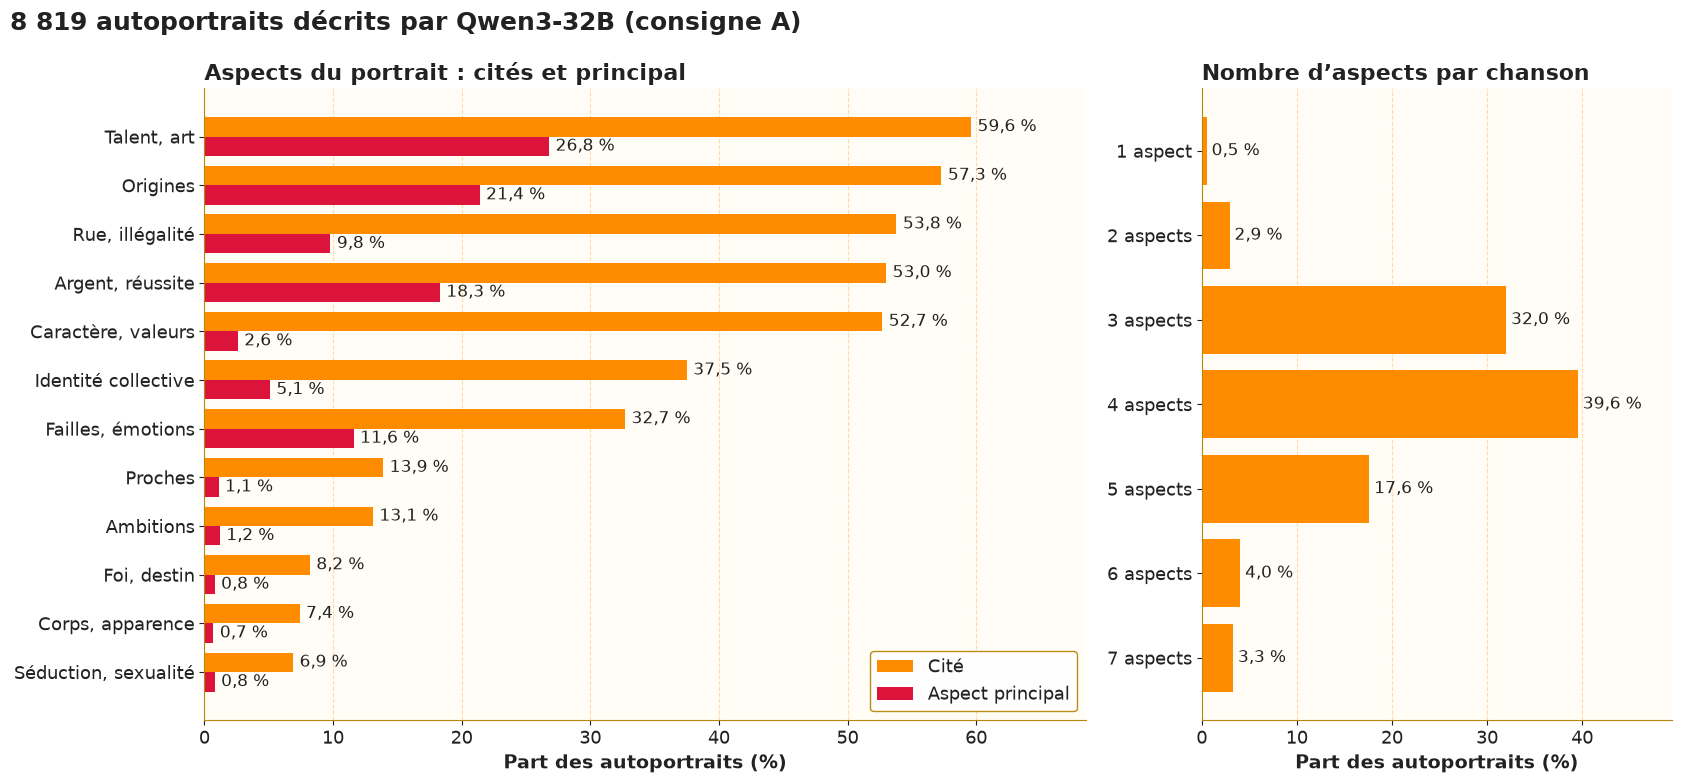

,aspect,libelle,cite,pourcentage_cite,principal,pourcentage_principal
0,talent_art,"Talent, art",5255,59.6,2362,26.8
1,origines,Origines,5057,57.3,1886,21.4
2,rue_illegalite,"Rue, illégalité",4748,53.8,866,9.8
3,argent_reussite,"Argent, réussite",4675,53.0,1610,18.3
4,caractere_valeurs,"Caractère, valeurs",4649,52.7,230,2.6
5,identite_collective,Identité collective,3303,37.5,446,5.1
6,failles_emotions,"Failles, émotions",2888,32.7,1027,11.6
7,proches,Proches,1224,13.9,93,1.1
8,ambitions,Ambitions,1155,13.1,102,1.2
9,foi_destin,"Foi, destin",720,8.2,69,0.8


,chansons,pourcentage
nombre_aspects,,
1,47,0.5
2,259,2.9
3,2823,32.0
4,3488,39.6
5,1554,17.6
6,357,4.0
7,291,3.3


Moyenne : 3.96 aspects par chanson.
Statistiques : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait2_qwen_description_8861_aspects.csv
Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait2_aspects_8861.png


In [14]:
# Cellule autonome : elle peut être exécutée seule, sans les étapes 0 à 4.
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

if 'dossier' not in globals():
    candidats = [Path.cwd(), Path.cwd() / 'Autoportrait', Path.cwd() / 'Rap' / 'Autoportrait']
    dossiers = [p.resolve() for p in candidats if (p / 'schema_A_description.json').is_file()]
    if len(dossiers) != 1:
        raise RuntimeError('Lancer le carnet depuis la racine du dépôt, Rap ou Rap/Autoportrait.')
    dossier = dossiers[0]
resultats_dir = dossier / 'data' / 'results'
schema_aspects = json.loads((dossier / 'schema_A_description.json').read_text(encoding='utf-8'))[
    'properties']['aspects']
modalites_aspects = schema_aspects['items']['enum']

# Palette hip-hop du dépôt (skill rap-eda-hip-hop-aesthetic), version fond clair :
# séries orange et cramoisi, axes or foncé (l'or vif est illisible sur blanc), texte gris foncé.
OR, ORANGE, CRAMOISI, FOND, FOND_AXES = '#B8860B', '#FF8C00', '#DC143C', '#FFFFFF', '#FFFDF5'
CITE, PRINCIPAL, TEXTE, GRILLE = ORANGE, CRAMOISI, '#222222', '#D9D9D9'
libelles_aspects = {
    'origines': 'Origines', 'argent_reussite': 'Argent, réussite', 'rue_illegalite': 'Rue, illégalité',
    'talent_art': 'Talent, art', 'corps_apparence': 'Corps, apparence', 'caractere_valeurs': 'Caractère, valeurs',
    'failles_emotions': 'Failles, émotions', 'foi_destin': 'Foi, destin', 'proches': 'Proches',
    'seduction_sexualite': 'Séduction, sexualité', 'ambitions': 'Ambitions', 'identite_collective': 'Identité collective',
}
def charger_aspects():
    lot_force = globals().get('n_analyse_force')
    if lot_force is not None and (type(lot_force) is not int or lot_force <= 0):
        raise ValueError('n_analyse_force doit être un entier positif, ou None pour le dernier export.')
    if lot_force is None:
        exports = [p for p in resultats_dir.glob('autoportrait2_qwen_description_*b.csv')
                   if p.stem.rsplit('_', 1)[1][:-1].isdigit()]
        if not exports:
            raise FileNotFoundError('Aucun export d’annotation « b » : exécuter l’étape 3.')
        dates = {p: p.stat().st_mtime_ns for p in exports}
        derniers = [p for p, date in dates.items() if date == max(dates.values())]
        if len(derniers) != 1:
            raise ValueError('Plusieurs exports ont la même date : choisir explicitement n_analyse_force.')
        chemin = derniers[0]
        lot = int(chemin.stem.rsplit('_', 1)[1][:-1])
    else:
        lot = lot_force
        chemin = resultats_dir / f'autoportrait2_qwen_description_{lot}b.csv'
    tableau = pd.read_csv(chemin, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    requises = {'source_row_index', 'annee', 'aspects'}
    if not requises <= set(tableau.columns):
        raise ValueError(f'{chemin.name} : colonnes absentes {sorted(requises - set(tableau.columns))}.')
    donnees = [{'annee': annee, 'aspects': aspects.split('|')}
               for annee, aspects in zip(tableau['annee'], tableau['aspects'])]
    inconnus = {a for d in donnees for a in d['aspects']} - set(modalites_aspects)
    if not donnees or inconnus:
        raise ValueError(f'{chemin.name} : aucune description valide ou aspects inconnus {sorted(inconnus)}.')
    if tableau['source_row_index'].duplicated().any():
        raise ValueError(f'{chemin.name} : chansons dupliquées.')
    if any(not schema_aspects['minItems'] <= len(d['aspects']) <= schema_aspects['maxItems']
           or len(set(d['aspects'])) != len(d['aspects']) for d in donnees):
        raise ValueError(f'{chemin.name} : listes d’aspects hors des bornes du schéma ou dupliquées.')
    print(f'Analyse de {chemin.name} : {len(donnees)} descriptions valides.'
          + (' Lot historique imposé.' if lot_force is not None else ' Dernier export d’annotation.'))
    return lot, chemin, tableau, donnees

n_analyse, analyse_path, analyse, analyses = charger_aspects()
total = len(analyses)
pourcent = lambda v: f'{v:.1f} %'.replace('.', ',')
principaux = pd.Series([d['aspects'][0] for d in analyses]).value_counts()
stats_aspects = pd.DataFrame([{
    'aspect': a, 'libelle': libelles_aspects.get(a, a),
    'cite': sum(a in d['aspects'] for d in analyses), 'principal': int(principaux.get(a, 0)),
} for a in modalites_aspects])
stats_aspects['pourcentage_cite'] = (100 * stats_aspects['cite'] / total).round(1)
stats_aspects['pourcentage_principal'] = (100 * stats_aspects['principal'] / total).round(1)
stats_aspects = stats_aspects[['aspect', 'libelle', 'cite', 'pourcentage_cite', 'principal', 'pourcentage_principal']]
stats_aspects = stats_aspects.sort_values('cite', ascending=False).reset_index(drop=True)
nombre_aspects = pd.Series([len(d['aspects']) for d in analyses]).value_counts().reindex(
    range(schema_aspects['minItems'], schema_aspects['maxItems'] + 1), fill_value=0)

aspects_path = resultats_dir / f'autoportrait2_qwen_description_{n_analyse}_aspects.csv'
stats_aspects.to_csv(aspects_path, index=False, encoding='utf-8')
images_dir = dossier / 'images'
images_dir.mkdir(exist_ok=True)
figure_path = images_dir / f'autoportrait2_aspects_{n_analyse}.png'

plt.rcParams.update({'text.color': TEXTE, 'axes.labelcolor': TEXTE, 'xtick.color': TEXTE, 'ytick.color': TEXTE,
                     'axes.edgecolor': OR, 'axes.facecolor': FOND_AXES, 'figure.facecolor': FOND,
                     'savefig.facecolor': FOND, 'legend.facecolor': FOND, 'legend.edgecolor': OR,
                     'axes.titleweight': 'bold', 'axes.labelweight': 'bold', 'font.size': 14,
                     'axes.titlesize': 16, 'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'legend.fontsize': 13, 'figure.titlesize': 18})
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={'width_ratios': [3, 1.6]}, facecolor=FOND)
ordre = stats_aspects.iloc[::-1]
y = range(len(ordre))
hauteur = 0.4
ax.barh([i + hauteur / 2 for i in y], ordre['pourcentage_cite'], height=hauteur, color=CITE, label='Cité')
ax.barh([i - hauteur / 2 for i in y], ordre['pourcentage_principal'], height=hauteur, color=PRINCIPAL,
        label='Aspect principal')
for i, (c, p) in enumerate(zip(ordre['pourcentage_cite'], ordre['pourcentage_principal'])):
    ax.text(c + 0.5, i + hauteur / 2, pourcent(c), va='center', fontsize=12)
    ax.text(p + 0.5, i - hauteur / 2, pourcent(p), va='center', fontsize=12)
ax.set_yticks(list(y), ordre['libelle'])
ax.set_xlabel('Part des autoportraits (%)')
ax.set_title('Aspects du portrait : cités et principal', loc='left', fontweight='bold')
ax.set_xlim(0, ordre['pourcentage_cite'].max() * 1.15)
ax.legend(loc='lower right', framealpha=0.95)

parts = 100 * nombre_aspects / total
ax2.barh([f'{k} aspect' + ('s' if k > 1 else '') for k in nombre_aspects.index][::-1], parts.values[::-1], color=CITE)
for i, v in enumerate(parts.values[::-1]):
    ax2.text(v + 0.5, i, pourcent(v), va='center', fontsize=12)
ax2.set_xlabel('Part des autoportraits (%)')
ax2.set_title('Nombre d’aspects par chanson', loc='left', fontweight='bold')
ax2.set_xlim(0, parts.max() * 1.25)
for axe in (ax, ax2):
    axe.grid(axis='x', color=ORANGE, alpha=0.3, linestyle='--', linewidth=0.8)
    axe.set_axisbelow(True)
    axe.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'{total:,} autoportraits'.replace(',', ' ') + f' décrits par Qwen3-32B (consigne A)', x=0.01, ha='left', color=TEXTE, fontweight='bold')
fig.tight_layout()
fig.savefig(figure_path, dpi=300, facecolor=FOND)
plt.show()

display(stats_aspects)
display(pd.DataFrame({'chansons': nombre_aspects, 'pourcentage': parts.round(1)}).rename_axis('nombre_aspects'))
print(f'Moyenne : {(nombre_aspects.index * nombre_aspects).sum() / total:.2f} aspects par chanson.')
print('Statistiques :', aspects_path)
print('Figure :', figure_path)

### 5.1 Similarité de Jaccard entre aspects

Exécuter les statistiques de l'étape 5 avant cette cellule. Jaccard = nombre de chansons contenant les deux aspects / nombre de chansons contenant au moins l'un des deux. L'indice varie de 0 à 1 et ignore les absences communes et le rang. Si les deux aspects sont absents du lot, l'indice est non défini (ND), y compris sur la diagonale.

Seuls le tableau de Jaccard et sa heatmap sont affichés. Export du tableau dans `data/results/` et de la figure dans `images/`. Le MDS se trouve dans la section suivante.


Analyse de autoportrait2_qwen_description_8861b.csv : 8819 descriptions valides. Dernier export d’annotation.
Similarité de Jaccard sur 8819 descriptions valides ; ND = union vide.


,Origines,"Argent, réussite","Rue, illégalité","Talent, art","Corps, apparence","Caractère, valeurs","Failles, émotions","Foi, destin",Proches,"Séduction, sexualité",Ambitions,Identité collective
aspect,,,,,,,,,,,,
Origines,1.000,0.332,0.419,0.431,0.020,0.420,0.239,0.070,0.101,0.040,0.112,0.248
"Argent, réussite",0.332,1.000,0.445,0.456,0.082,0.316,0.160,0.045,0.106,0.066,0.067,0.223
"Rue, illégalité",0.419,0.445,1.000,0.394,0.055,0.402,0.181,0.067,0.099,0.050,0.066,0.231
"Talent, art",0.431,0.456,0.394,1.000,0.058,0.347,0.149,0.049,0.083,0.048,0.097,0.288
"Corps, apparence",0.020,0.082,0.055,0.058,1.000,0.026,0.060,0.022,0.042,0.057,0.030,0.042
"Caractère, valeurs",0.420,0.316,0.402,0.347,0.026,1.000,0.209,0.088,0.115,0.052,0.097,0.279
"Failles, émotions",0.239,0.160,0.181,0.149,0.060,0.209,1.000,0.081,0.174,0.051,0.149,0.184
"Foi, destin",0.070,0.045,0.067,0.049,0.022,0.088,0.081,1.000,0.096,0.043,0.074,0.101
Proches,0.101,0.106,0.099,0.083,0.042,0.115,0.174,0.096,1.000,0.037,0.091,0.075


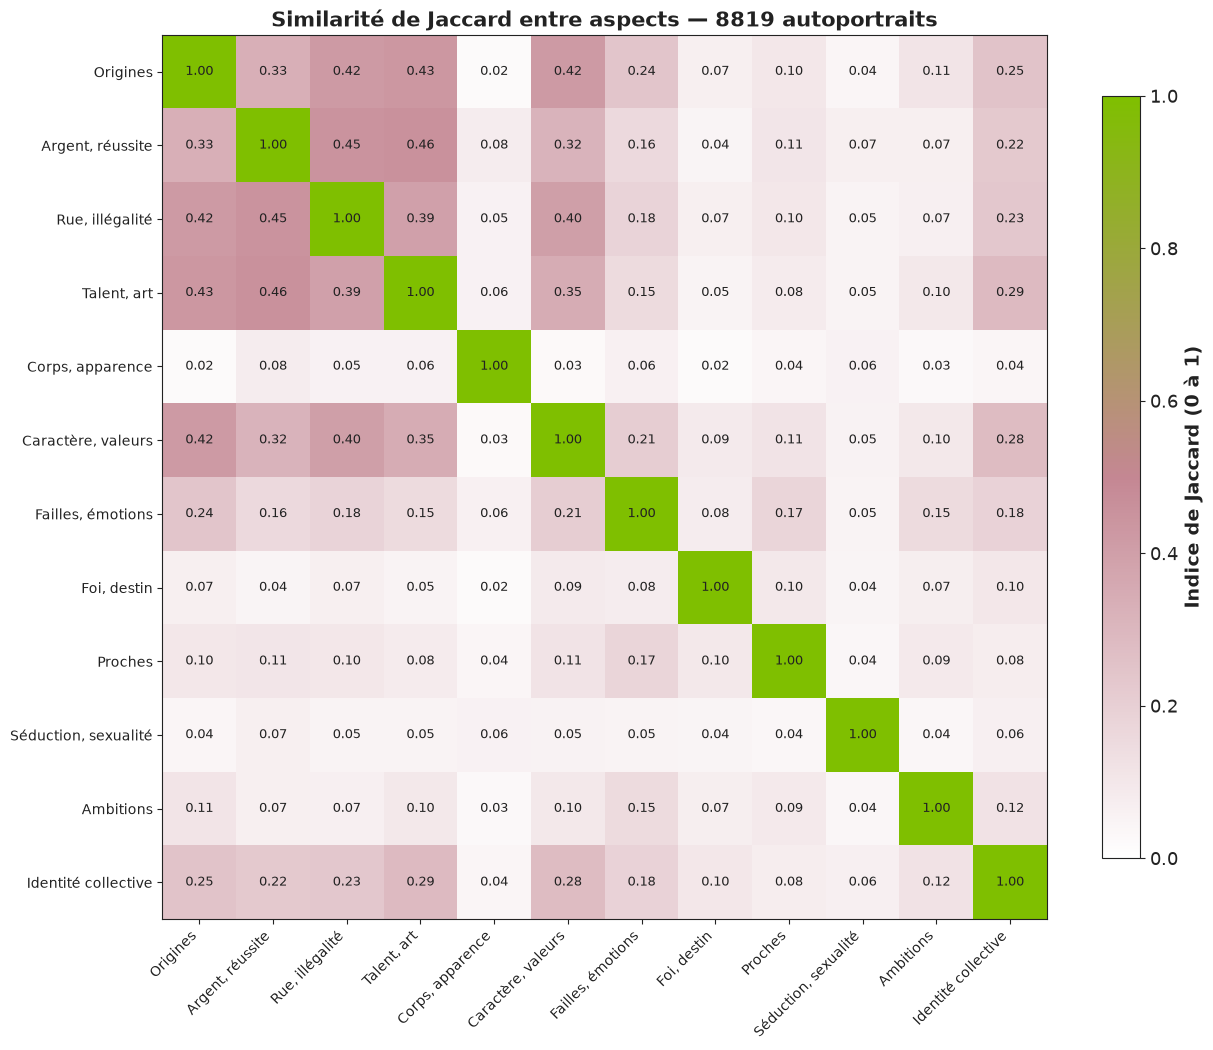

Similarités : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait2_qwen_description_8861_jaccard.csv
Heatmap : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait2_aspects_jaccard_8861.png


In [15]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

if 'charger_aspects' not in globals():
    raise RuntimeError('Exécuter les statistiques des aspects (étape 5) avant Jaccard.')
n_analyse, analyse_path, analyse, analyses = charger_aspects()
binaire_jaccard = pd.DataFrame(
    [[int(aspect in d['aspects']) for aspect in modalites_aspects] for d in analyses],
    columns=modalites_aspects, dtype='int64')
intersections_jaccard = binaire_jaccard.T.dot(binaire_jaccard)
presences_jaccard = binaire_jaccard.sum().to_numpy()
unions_jaccard = presences_jaccard[:, None] + presences_jaccard[None, :] - intersections_jaccard.to_numpy()
similarites_jaccard = np.divide(intersections_jaccard.to_numpy(), unions_jaccard,
    out=np.full(unions_jaccard.shape, np.nan), where=unions_jaccard > 0)
jaccard_aspects = pd.DataFrame(similarites_jaccard,
    index=pd.Index(modalites_aspects, name='aspect'), columns=modalites_aspects)
lot_jaccard = analyse_path.stem.removeprefix('autoportrait2_qwen_description_').removesuffix('b')
jaccard_path = resultats_dir / f'autoportrait2_qwen_description_{lot_jaccard}_jaccard.csv'
jaccard_aspects.to_csv(jaccard_path, encoding='utf-8', na_rep='ND')
print(f'Similarité de Jaccard sur {len(analyses)} descriptions valides ; ND = union vide.')
display(jaccard_aspects.rename(index=libelles_aspects, columns=libelles_aspects).round(3))

palette_jaccard = LinearSegmentedColormap.from_list('jaccard', ['#FFFFFF', '#C48793', '#7FBF00'])
palette_jaccard.set_bad('#D9D9D9')
with plt.rc_context({'text.color': '#222222', 'axes.labelcolor': '#222222',
                     'xtick.color': '#222222', 'ytick.color': '#222222',
                     'axes.edgecolor': '#222222', 'figure.facecolor': '#FFFFFF'}):
    fig_jaccard, ax_jaccard = plt.subplots(figsize=(13, 11))
    image_jaccard = ax_jaccard.imshow(np.ma.masked_invalid(similarites_jaccard),
                                    cmap=palette_jaccard, vmin=0, vmax=1)
    labels_jaccard = [libelles_aspects.get(a, a) for a in modalites_aspects]
    ax_jaccard.set_xticks(range(len(labels_jaccard)), labels_jaccard, rotation=45, ha='right', fontsize=10)
    ax_jaccard.set_yticks(range(len(labels_jaccard)), labels_jaccard, fontsize=10)
    for i, j in np.ndindex(similarites_jaccard.shape):
        valeur_jaccard = similarites_jaccard[i, j]
        label_jaccard = 'ND' if np.isnan(valeur_jaccard) else f'{valeur_jaccard:.2f}'
        ax_jaccard.text(j, i, label_jaccard, ha='center', va='center', color='#222222', fontsize=9)
    ax_jaccard.set_title(f'Similarité de Jaccard entre aspects — {len(analyses)} autoportraits', fontsize=15)
    fig_jaccard.colorbar(image_jaccard, ax=ax_jaccard, shrink=0.8, label='Indice de Jaccard (0 à 1)')
    fig_jaccard.tight_layout()
    figure_jaccard_path = images_dir / f'autoportrait2_aspects_jaccard_{lot_jaccard}.png'
    fig_jaccard.savefig(figure_jaccard_path, dpi=300, facecolor='#FFFFFF')
    plt.show()
print('Similarités :', jaccard_path)
print('Heatmap :', figure_jaccard_path)


### 5.2 Projection MDS des aspects

Exécuter les statistiques de l'étape 5 avant cette section. Même matrice binaire que
les sections 5.1 et 5.2 : une ligne par description valide, une colonne par aspect.

L'association entre deux aspects est mesurée par le **coefficient phi** (corrélation
de Pearson entre indicatrices 0/1) ; la dissimilarité vaut `1 - phi`. La projection
est un **MDS métrique classique (PCoA, Torgerson)** calculé par double centrage et
décomposition spectrale : le résultat est déterministe, sans graine ni dépendance
supplémentaire. Chaque aspect est représenté par un **double point superposé** : le cercle
orange est proportionnel à la **part des chansons qui citent l'aspect**, le
disque cramoisi, posé dessus, à la **part où il est principal** (premier
rang). L'écart entre les deux surfaces distingue la diffusion d'un thème de
sa centralité. Les axes ne s'interprètent que par les proximités :
deux aspects proches tendent à être cités dans les mêmes chansons.

La matrice phi et les coordonnées sont exportées dans `data/results/`, la figure
dans `images/`. Aucune inférence n'est lancée.


Analyse de autoportrait2_qwen_description_8861b.csv : 8819 descriptions valides. Dernier export d’annotation.
MDS classique (PCoA) sur 8819 descriptions valides ; variance positive restituée par le plan : 38.4 %.


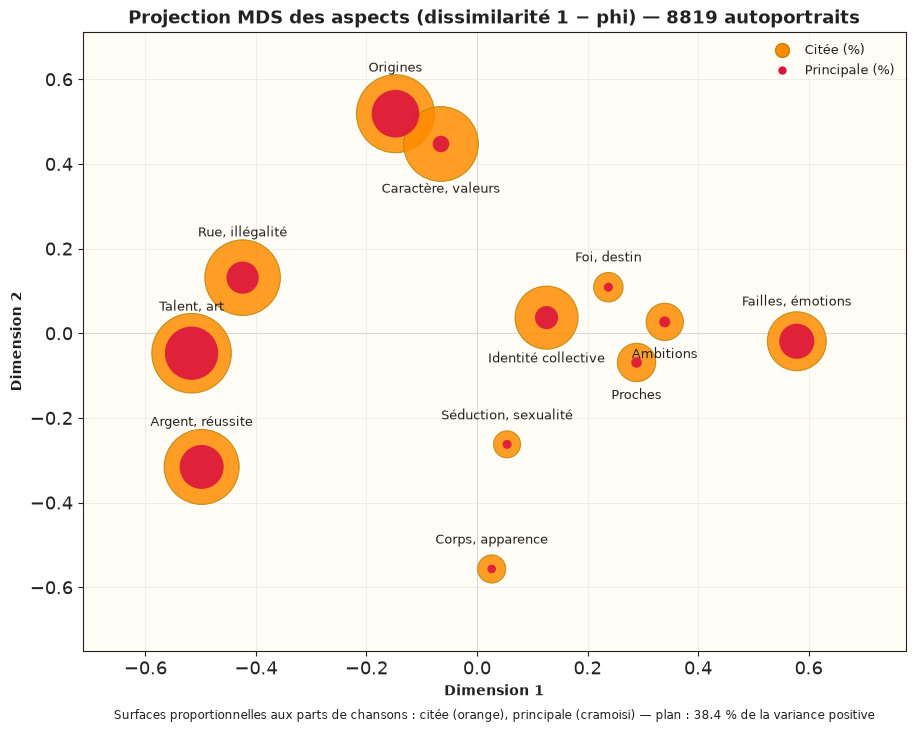

Phi : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait2_qwen_description_8861_phi.csv
Coordonnées : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait2_qwen_description_8861_mds.csv
Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait2_aspects_mds_8861.png


In [18]:
import numpy as np

if 'charger_aspects' not in globals():
    raise RuntimeError('Exécuter les statistiques des aspects (étape 5) avant le MDS.')
n_analyse, analyse_path, analyse, analyses = charger_aspects()
matrice_mds = pd.DataFrame(
    [[int(aspect in d['aspects']) for aspect in modalites_aspects] for d in analyses],
    columns=modalites_aspects, dtype='float64')
ecarts_mds = matrice_mds.std(ddof=1)
aspects_constants_mds = ecarts_mds.index[ecarts_mds.eq(0)].tolist()
if aspects_constants_mds:
    print('Aspects constants exclus du MDS :', ', '.join(aspects_constants_mds))
aspects_mds = ecarts_mds.index[ecarts_mds.gt(0)].tolist()
if len(aspects_mds) < 3:
    raise ValueError('Le MDS nécessite au moins trois aspects non constants.')

phi_mds = np.corrcoef(matrice_mds[aspects_mds].to_numpy(), rowvar=False)
lot_mds = analyse_path.stem.removeprefix('autoportrait2_qwen_description_').removesuffix('b')
phi_path = resultats_dir / f'autoportrait2_qwen_description_{lot_mds}_phi.csv'
pd.DataFrame(phi_mds, index=pd.Index(aspects_mds, name='aspect'),
             columns=aspects_mds).round(4).to_csv(phi_path, encoding='utf-8')

# MDS métrique classique (PCoA) : double centrage de D², axes propres positifs.
dissimilarites_mds = 1.0 - phi_mds
np.fill_diagonal(dissimilarites_mds, 0.0)
nb_aspects_mds = len(aspects_mds)
centrage_mds = np.eye(nb_aspects_mds) - np.full((nb_aspects_mds, nb_aspects_mds), 1.0 / nb_aspects_mds)
b_mds = -0.5 * centrage_mds @ (dissimilarites_mds ** 2) @ centrage_mds
valeurs_mds, vecteurs_mds = np.linalg.eigh(b_mds)
ordre_mds = np.argsort(valeurs_mds)[::-1]
valeurs_mds, vecteurs_mds = valeurs_mds[ordre_mds], vecteurs_mds[:, ordre_mds]
if valeurs_mds[1] <= 0:
    raise ValueError('Moins de deux axes positifs : projection 2D impossible.')
coordonnees_mds = vecteurs_mds[:, :2] * np.sqrt(valeurs_mds[:2])
part_mds = valeurs_mds[:2].sum() / valeurs_mds[valeurs_mds > 0].sum()

principaux_mds = pd.Series([d['aspects'][0] for d in analyses])
citees_mds = 100.0 * matrice_mds[aspects_mds].mean().to_numpy()
principales_mds = np.array([100.0 * (principaux_mds == a).mean() for a in aspects_mds])
libelles_mds = [libelles_aspects.get(a, a) for a in aspects_mds]
mds_path = resultats_dir / f'autoportrait2_qwen_description_{lot_mds}_mds.csv'
pd.DataFrame({'aspect': libelles_mds,
              'dim1': np.round(coordonnees_mds[:, 0], 4),
              'dim2': np.round(coordonnees_mds[:, 1], 4),
              'cite_pct': np.round(citees_mds, 1),
              'principal_pct': np.round(principales_mds, 1)}).to_csv(
    mds_path, index=False, encoding='utf-8')
print(f'MDS classique (PCoA) sur {len(analyses)} descriptions valides ; '
      f'variance positive restituée par le plan : {100 * part_mds:.1f} %.')

with plt.rc_context({'text.color': '#222222', 'axes.labelcolor': '#222222',
                     'xtick.color': '#222222', 'ytick.color': '#222222',
                     'axes.edgecolor': '#222222', 'figure.facecolor': '#FFFFFF'}):
    fig_mds, ax_mds = plt.subplots(figsize=(9.5, 7.5))
    ax_mds.set_facecolor('#FFFDF5')
    ax_mds.scatter(coordonnees_mds[:, 0], coordonnees_mds[:, 1],
                   s=citees_mds * 55, c='#FF8C00', edgecolors='#B8860B',
                   linewidths=0.8, alpha=0.85, zorder=3, label='Citée (%)')
    ax_mds.scatter(coordonnees_mds[:, 0], coordonnees_mds[:, 1],
                   s=np.maximum(principales_mds * 55, 4), c='#DC143C', edgecolors='none',
                   alpha=0.9, zorder=4, label='Principale (%)')
    for i_mds, ((x_mds, y_mds), nom_mds, f_mds) in enumerate(
            zip(coordonnees_mds, libelles_mds, citees_mds)):
        rayon_mds = 0.03 + 0.0011 * np.sqrt(f_mds * 55)
        # Étiquette sous le point si un voisin proche se trouve au-dessus.
        voisin_haut = any(
            j_mds != i_mds
            and np.hypot(cx_mds - x_mds, cy_mds - y_mds) < 0.15
            and cy_mds >= y_mds
            for j_mds, (cx_mds, cy_mds) in enumerate(coordonnees_mds))
        if voisin_haut:
            ax_mds.annotate(nom_mds, (x_mds, y_mds), xytext=(x_mds, y_mds - rayon_mds),
                            ha='center', va='top', fontsize=9.5, zorder=5)
        else:
            ax_mds.annotate(nom_mds, (x_mds, y_mds), xytext=(x_mds, y_mds + rayon_mds),
                            ha='center', va='bottom', fontsize=9.5, zorder=5)
    poignees_mds = [
        plt.Line2D([0], [0], marker='o', color='none', markerfacecolor='#FF8C00',
                   markeredgecolor='#B8860B', markersize=10, label='Citée (%)'),
        plt.Line2D([0], [0], marker='o', color='none', markerfacecolor='#DC143C',
                   markeredgecolor='none', markersize=6, label='Principale (%)')]
    ax_mds.legend(handles=poignees_mds, loc='upper right', fontsize=9, frameon=False)
    ax_mds.axhline(0, color='#D9D9D9', linewidth=0.8, zorder=1)
    ax_mds.axvline(0, color='#D9D9D9', linewidth=0.8, zorder=1)
    ax_mds.grid(color='#D9D9D9', linewidth=0.5, alpha=0.6, zorder=0)
    ax_mds.set_title(f'Projection MDS des aspects (dissimilarité 1 − phi) — '
                     f'{len(analyses)} autoportraits', fontsize=13)
    ax_mds.set_xlabel('Dimension 1', fontsize=10)
    ax_mds.set_ylabel('Dimension 2', fontsize=10)
    ax_mds.annotate('Surfaces proportionnelles aux parts de chansons : citée (orange), principale (cramoisi) — '
                    f'plan : {100 * part_mds:.1f} % de la variance positive',
                    xy=(0.5, -0.11), xycoords='axes fraction', ha='center', fontsize=8.5)
    marge_x_mds = 0.18 * np.ptp(coordonnees_mds[:, 0])
    marge_y_mds = 0.18 * np.ptp(coordonnees_mds[:, 1])
    ax_mds.set_xlim(coordonnees_mds[:, 0].min() - marge_x_mds, coordonnees_mds[:, 0].max() + marge_x_mds)
    ax_mds.set_ylim(coordonnees_mds[:, 1].min() - marge_y_mds, coordonnees_mds[:, 1].max() + marge_y_mds)
    fig_mds.tight_layout()
    figure_mds_path = images_dir / f'autoportrait2_aspects_mds_{lot_mds}.png'
    fig_mds.savefig(figure_mds_path, dpi=300, facecolor='#FFFFFF')
    plt.show()
print('Phi :', phi_path)
print('Coordonnées :', mds_path)
print('Figure :', figure_mds_path)

## 6. Évolution des aspects dans le temps (lissage)

Même sélection automatique que l'étape 5 ; le CSV est rechargé à chaque exécution. Exécuter l'étape 5 une fois pour définir le chargeur.

Pour chaque aspect, part annuelle des autoportraits qui le **citent** (points orange), courbe
**lissée** de cette part (trait orange) et courbe lissée de la part où il est l'**aspect
principal** (trait cramoisi), sur fond clair (palette hip-hop du dépôt). Un panneau par aspect, triés par fréquence de citation ; chaque
panneau a sa propre échelle verticale (partant de 0) pour rendre lisibles les aspects rares.

**Lissage** : moyenne mobile centrée sur `fenetre_lissage` années (5 par défaut, réglable en tête de
cellule), calculée en **cumulant les effectifs** de la fenêtre (chansons qui citent l'aspect / chansons
décrites) plutôt qu'en moyennant les pourcentages annuels. Les années peu fournies (1990–1994 : moins de
25 autoportraits chacune) pèsent donc selon leur effectif réel et ne créent pas de pics artificiels.
Aux bords de la période, la fenêtre est tronquée (`min_periods=1`). Les premières années (1990–1994) restent
fragiles malgré le cumul : à lire avec prudence.

Un tableau compare enfin trois périodes (1990–2003, 2004–2013, 2014–2024) : part des autoportraits
citant chaque aspect, effectifs cumulés sur la période, et écart en points entre la première et la
dernière, trié de la plus forte hausse à la plus forte baisse.

La ligne verticale pointillée marque 2004, seuil du corpus d'étude : toutes les chansons avant,
500 tirées par an ensuite. Les années sans date (NA) sont écartées.

Exports :

- `data/results/autoportrait2_qwen_description_{n}_aspects_par_annee.csv` (colonnes `annee, aspect,
  chansons, cite, principal, pourcentage_cite, pourcentage_cite_lisse, pourcentage_principal_lisse`) ;
- `images/autoportrait2_aspects_evolution_{n}.png`.

Analyse de autoportrait2_qwen_description_8861b.csv : 8819 descriptions valides. Dernier export d’annotation.


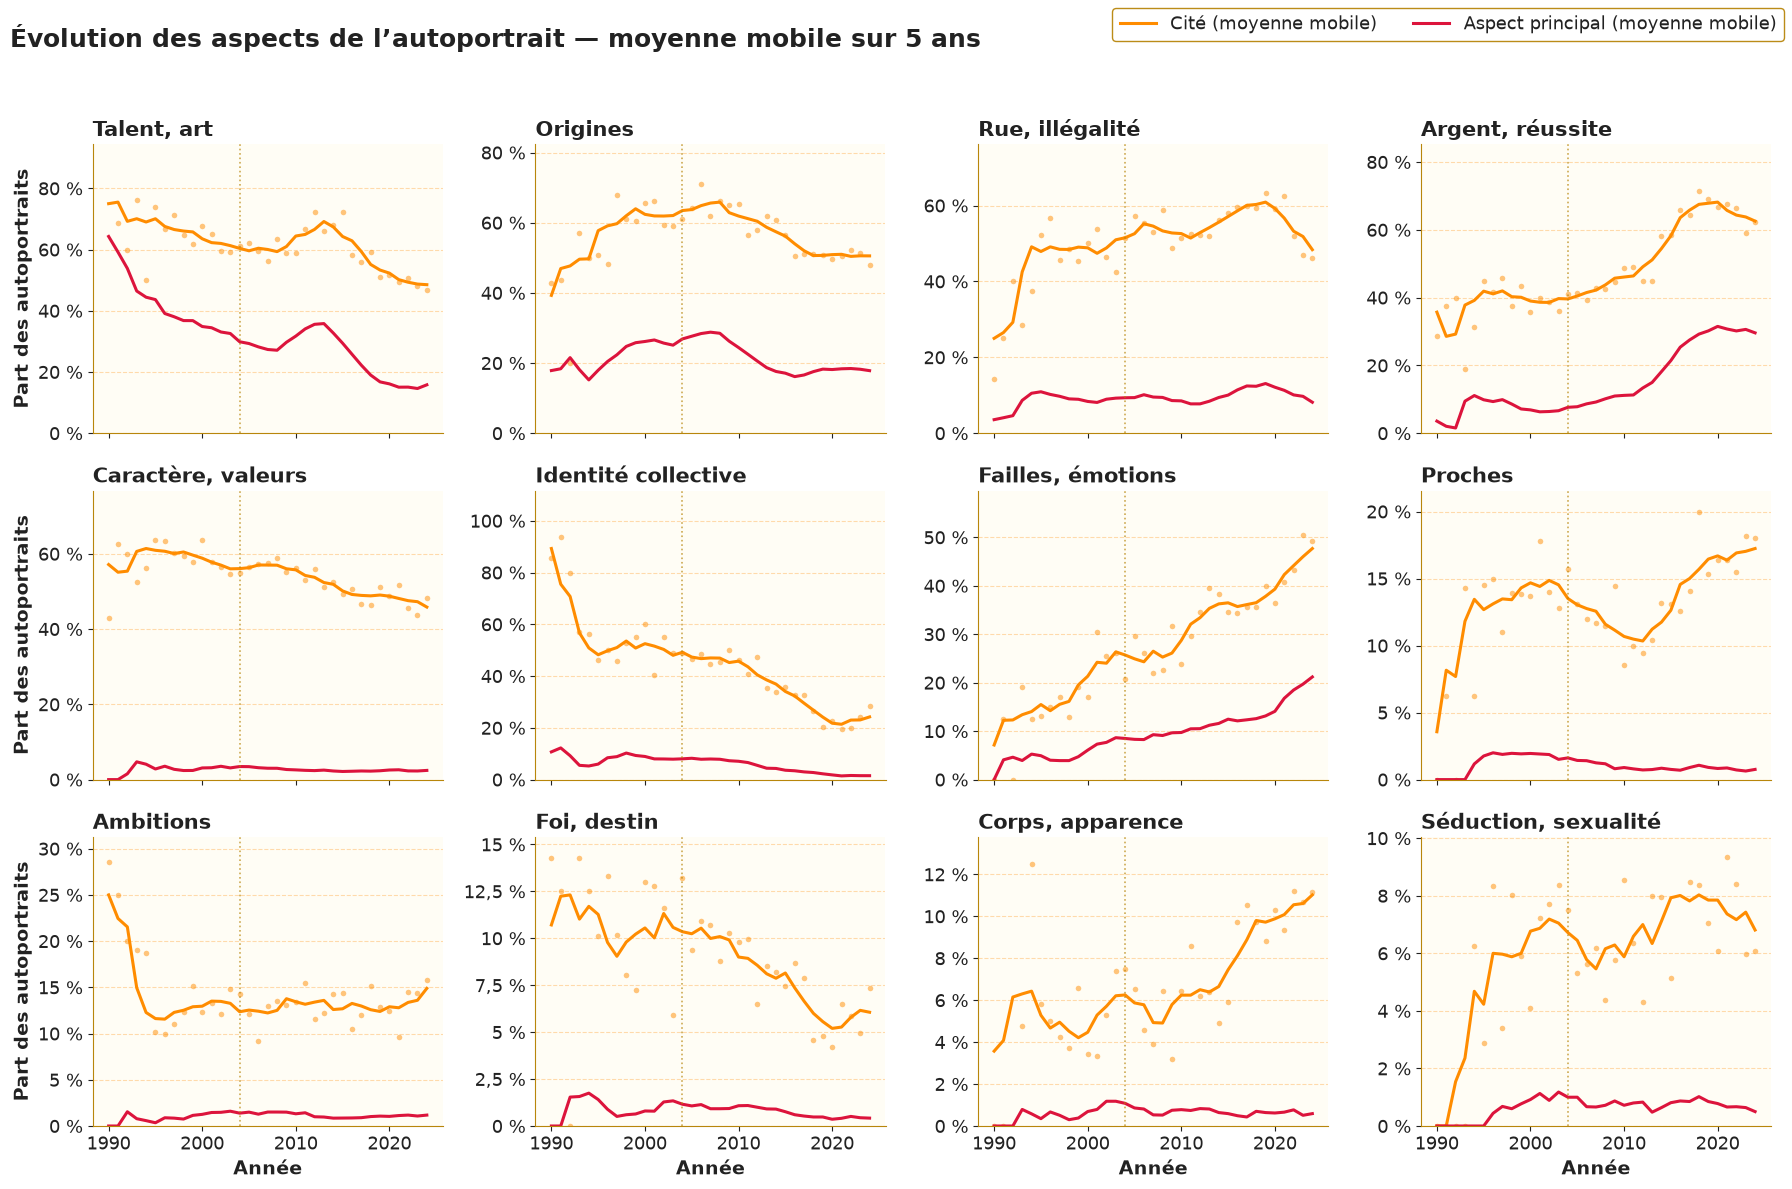

Part des autoportraits citant chaque aspect, par période (effectifs cumulés, %) :


,libelle,1990–2003,2004–2013,2014–2024,ecart_points
aspect,,,,,
argent_reussite,"Argent, réussite",39.1,44.1,64.5,25.4
failles_emotions,"Failles, émotions",20.5,28.5,40.1,19.6
rue_illegalite,"Rue, illégalité",47.2,53.2,56.5,9.3
corps_apparence,"Corps, apparence",5.0,6.0,9.3,4.3
proches,Proches,13.8,11.5,15.7,1.9
seduction_sexualite,"Séduction, sexualité",6.3,6.2,7.5,1.2
ambitions,Ambitions,13.2,12.8,13.3,0.1
foi_destin,"Foi, destin",10.0,9.7,6.4,-3.6
origines,Origines,60.5,62.9,52.0,-8.5


Évolution : /home/cbenavent/test/Rap/Autoportrait/data/results/autoportrait2_qwen_description_8861_aspects_par_annee.csv
Figure : /home/cbenavent/test/Rap/Autoportrait/images/autoportrait2_aspects_evolution_8861.png


In [19]:
fenetre_lissage = 5   # années de la moyenne mobile centrée

if 'charger_aspects' not in globals():
    raise RuntimeError('Exécuter les statistiques des aspects (étape 5) avant l’évolution.')
n_analyse, analyse_path, analyse, analyses = charger_aspects()
total = len(analyses)

par_annee_aspects = pd.DataFrame([
    {'annee': int(d['annee']), 'aspect': a, 'cite': int(a in d['aspects']), 'principal': int(d['aspects'][0] == a)}
    for d in analyses if str(d['annee']).isdigit() for a in modalites_aspects])
evolution = (par_annee_aspects.groupby(['aspect', 'annee'])
             .agg(chansons=('cite', 'size'), cite=('cite', 'sum'), principal=('principal', 'sum')).reset_index())
lisser = lambda s: s.rolling(fenetre_lissage, center=True, min_periods=1).sum()
evolution = evolution.sort_values(['aspect', 'annee'])
groupes = evolution.groupby('aspect', group_keys=False)
evolution['pourcentage_cite'] = (100 * evolution['cite'] / evolution['chansons']).round(2)
evolution['pourcentage_cite_lisse'] = (100 * groupes['cite'].transform(lisser)
                                       / groupes['chansons'].transform(lisser)).round(2)
evolution['pourcentage_principal_lisse'] = (100 * groupes['principal'].transform(lisser)
                                            / groupes['chansons'].transform(lisser)).round(2)
evolution_path = resultats_dir / f'autoportrait2_qwen_description_{n_analyse}_aspects_par_annee.csv'
evolution.to_csv(evolution_path, index=False, encoding='utf-8')

ordre_aspects = sorted(modalites_aspects, key=lambda a: sum(a in d['aspects'] for d in analyses), reverse=True)
fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharex=True, facecolor=FOND)
for ax, aspect in zip(axes.flat, ordre_aspects):
    serie = evolution.loc[evolution['aspect'] == aspect]
    ax.scatter(serie['annee'], serie['pourcentage_cite'], s=16, color=CITE, alpha=0.5, linewidths=0)
    ax.plot(serie['annee'], serie['pourcentage_cite_lisse'], color=CITE, linewidth=2.2, label='Cité (lissé)')
    ax.plot(serie['annee'], serie['pourcentage_principal_lisse'], color=PRINCIPAL, linewidth=2.2,
            label='Principal (lissé)')
    ax.axvline(2004, color=OR, linestyle=':', linewidth=1.2, alpha=0.7)
    ax.set_title(libelles_aspects.get(aspect, aspect), loc='left', fontsize=15, fontweight='bold')
    ax.set_ylim(0, max(serie['pourcentage_cite_lisse'].max(), 1) * 1.25)
    ax.grid(axis='y', color=ORANGE, alpha=0.3, linestyle='--', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:g} %'.replace('.', ','))
for ax in axes[-1]:
    ax.set_xlabel('Année')
for ax in axes[:, 0]:
    ax.set_ylabel('Part des autoportraits')
poignees, etiquettes = axes.flat[0].get_legend_handles_labels()
fig.legend(poignees, ['Cité (moyenne mobile)', 'Aspect principal (moyenne mobile)'], loc='upper right',
           ncol=2, framealpha=0.95)
fig.suptitle(f'Évolution des aspects de l’autoportrait — moyenne mobile sur {fenetre_lissage} ans',
             x=0.01, ha='left', color=TEXTE, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.96))
evolution_figure_path = images_dir / f'autoportrait2_aspects_evolution_{n_analyse}.png'
fig.savefig(evolution_figure_path, dpi=300, facecolor=FOND)
plt.show()

periodes_tendance = {'1990–2003': (1990, 2003), '2004–2013': (2004, 2013), '2014–2024': (2014, 2024)}
tendance = pd.DataFrame({
    nom: evolution.loc[evolution['annee'].between(a, b)].groupby('aspect').apply(
        lambda g: 100 * g['cite'].sum() / g['chansons'].sum(), include_groups=False)
    for nom, (a, b) in periodes_tendance.items()}).reindex(ordre_aspects).round(1)
tendance.insert(0, 'libelle', [libelles_aspects[a] for a in ordre_aspects])
tendance['ecart_points'] = (tendance['2014–2024'] - tendance['1990–2003']).round(1)
print('Part des autoportraits citant chaque aspect, par période (effectifs cumulés, %) :')
display(tendance.sort_values('ecart_points', ascending=False))
print('Évolution :', evolution_path)
print('Figure :', evolution_figure_path)